### Constriction Benchmark

This benchmark simulates the constriction of a channel of a superheated flow.

In [1]:
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.insert(0,"/home/jovyan/shared/Libraries")
import victor
import subprocess
import os

### To choose between levels of flux, please specify 

In [2]:
easting = 750
northing = 500
dem = "DEMs_PDC_Benchmark/constriction_arc.asc"
raster = rxr.open_rasterio(dem)
raster = raster.sel({"band": 1})
xll, yll = float(raster.x.min()), float(raster.y.min())
coordinates = np.array([int(easting),int(northing)])
res = raster.rio.resolution()[0]

## Volcflow

### An open source varient running on Octave

In [7]:
os.chdir("/home/jovyan/PDC Benchmark/VolcFlow")
f = open("toposcript.m","r+")
inp = f.readlines()
inp[0] = f"fid = fopen('../DEMs_PDC_Benchmark/constriction_arc.grd');\n"
inp[24] = f"dtplot = 1;\n"
inp[25] = f"tmax = 100;\n"
inp[36] = f"V={1e6};\n"
inp[38] = f"r=5;\n"
inp[42] = "jh=100; ih=150;\n"
f.seek(0)
f.writelines(inp)
f.truncate()
f.close()

g = open("output_script.m",'r+')
inp = g.readlines()
inp[0] = "fid = fopen('../DEMs_PDC_Benchmark/constriction_arc.grd');\n"
inp[15] = "out=fopen('constriction_output.grd','wb');\n"
g.seek(0)
g.writelines(inp)
g.truncate()
g.close()

process = subprocess.Popen(
    ["matlab", "-batch", "VF_run"],
    stderr=subprocess.DEVNULL
)
os.chdir("..")




     ___________  Version n° 4.0.0   ___________
     |                                                 |
     | VolcFlow is a numerical code for the simulation |
     |  of geophysical flows on complex topographies.  |
     |          It is written by Karim Kelfoun,        |
     |      Laboratoire Magmas et Volcans, UMR 6524    |
     |           Clermont-Auvergne University          |
     |      6, avenue Blaise Pascal, 63170 Aubière     |
     |           <a href = "http://https://lmv.uca.fr/volcflow/">Visit the VolcFlow web site.</a>          |
     |                                                 |
     |   ---       License : Karim Kelfoun       ---   |
     ¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯¯

ans =

     0

The center of mass is located in i=NaN, j=NaN (in meshes).
Warning ! With a variable time step, dt should be defined so that: dt×2^n = dtplot ! Corrected value: dt = 0.125000 ! 


VolcFlow is now running...
time :    0.000 s., dt =     0.13 s., v max = 

### IMEX_SfloW_2D

In [9]:
os.chdir("/home/jovyan/PDC Benchmark/IMEX_SfloW_2D")

f=open("./IMEX_SfloW2D.inp","r+")
inp = f.readlines()
inp[1] =  'RUN_NAME="constriction_arc",\n'
inp[2] =  f"""RESTART=F,\n"""
inp[3] =  f"""T_START=  0     ,\n"""
inp[4] =  f"""T_END=  100,\n"""
inp[5] =  f"""DT_OUTPUT=  10,\n"""
inp[13] = f""" X0={xll},\n"""
inp[14] = f""" Y0=  {yll}     ,\n"""
inp[15] = f" TOPOGRAPHY_FILE = 'constriction_arc.asc' ,\n"
inp[16] = f""" COMP_CELLS_X=  300,\n"""
inp[17] = f""" COMP_CELLS_Y=  1000,	\n"""
inp[18] = f""" CELL_SIZE = 5.0D0    ,\n"""
inp[103] = f" X_SOURCE = {easting} ,\n"
inp[104] = f" Y_SOURCE = {northing} ,\n"
inp[105] = " H_SOURCE = 2.5D0 ,\n"
inp[106] = " R_SOURCE = 10.0D0 ,\n"
inp[107] = " VEL_SOURCE = 65.0D0 ,\n"
inp[108] = " T_SOURCE = 350.0D0 , \n"
inp[109] = "ALPHAS_SOURCE = 0.02D0 ,\n "
f.seek(0)
f.writelines(inp)
f.truncate()
f.close()

p = subprocess.Popen(['./IMEX_SfloW2D'], stdin=subprocess.PIPE, shell=True)
os.chdir("..")

 ---------------------
 IMEX_SfloW2D 2.0
 ---------------------
 NOTE: PORE_PRESSURE_FLAG is FALSE. Pore pressure equation will not be solved.
 HYDRAULIC_PERMEABILITY, F_INHIBIT_MODE, ALPHA_TRANS, and PORE_PRESSURE_FRACTION will not be accounted for.
 GAS_LOSS_FLAG and DYNAMIC_PERMEABILITY_FLAG will be set to FALSE.
 Run name: constriction_arc                        
 ----- 2D SIMULATION -----
 CARRIER PHASE: gas
 Carrier phase kinematic viscosity:   1.4800000000000001E-005
 Ambient density =    1.1763298740177413       (kg/m3)

 Initial erodible thickness set to 0

 Model variables =            5
 Linear reconstruction and b. c. applied to variables:
 h,hu,hv,T,halphas
 Searching for DEM file
 Reading DEM file
 ncols         300
 nrows        1000
 Percent Complete: 100.00% 
 IOSTAT=          -1
 thickness_levels          -1
 dyn_pres_levels          -1
 source_length =    62.831853071795862     

 time_param =  -1.0000000000000000       -1.0000000000000000       -1.0000000000000000  

### TITAN2D

In [ ]:
os.chdir("/home/jovyan/PDC Benchmark/Titan2D")

f=open("./input.py","r+")
inp = f.readlines()
inp[4] = "    gis_map='../DEMs_PDC_Benchmark/constriction_arc.asc',\n"
inp[25] = "     influx=31.83,\n"
inp[26] = "    start_time=0.0,\n"
inp[27] = "   end_time=100.0,\n"
inp[28] = "    center=[750.0, 500.0],\n"
f.seek(0)
f.writelines(inp)
f.truncate()
f.close()

process = subprocess.Popen(
    "./titan -nt 4 input.py",
    shell=True,
    stderr=subprocess.DEVNULL,
    stdout=subprocess.PIPE,
    text=True
)

Python home: /srv/conda/envs/notebook
Executable location: /home/jovyan/shared/Models/titan2d/bin/titan
python home: /srv/conda/envs/notebook
Titan2d 4.1.0
Executable location: /home/jovyan/shared/Models/titan2d/bin/titan
-------------------------------------------------------------------------------

Set threads number to 1


preproc...
The GIS region is:  x = 0.000000e+00 to 1.500000e+03   y = 0.000000e+00 to 5.000000e+03.
The simulation region is:  x = 0.000000e+00 to 1.500000e+03   y = 0.000000e+00 to 5.000000e+03.

GIS:
	gis_format: 2
	gis_main: 
	gis_sub: 
	gis_mapset: 
	gis_map: ../DEMs_PDC_Benchmark/constriction_arc.asc
	gis_vector: 
	extramaps: 0
	region_limits_set 0
Piles:    there is no piles
Flux sources:    (Number of flux sources: 1)
	Flux_source 0:
		Extrusion flux rate [m/s]:31.830000
		Active Time [s], start, end: 0.000000 100.000000
		Center of Initial Volume, xc, yc (UTM E, UTM N): 750.000000 500.000000
		Major and Minor Extent, majorR, minorR (m, m): 25.000000 25.00

In [4]:
os.chdir("/home/jovyan/PDC Benchmark/Titan2D")
f=open("./conv2.R","r+")
inp = f.readlines()
inp[19] = 'mydir="/home/jovyan/PDC Benchmark/Titan2D"\n'
inp[21] = 'convert<-function(filename="constriction.asc",calcCellsize=TRUE,cellsize=5,NODATA_value="-9999")'
f.seek(0)
f.writelines(inp)
f.truncate()
f.close()

!Rscript conv2.R

[1] "Beginning to create table, please wait..."
[1] "All done! File is in directory:"    "/home/jovyan/PDC Benchmark/Titan2D"


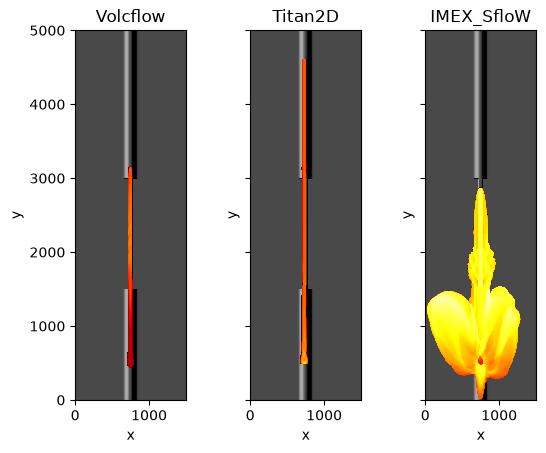

In [10]:
os.chdir("/home/jovyan/PDC Benchmark")

volcflow = rxr.open_rasterio("VolcFlow/constriction_output.grd",masked=True)
a = volcflow.max()
titan2d = rxr.open_rasterio("Titan2D/constriction.asc",masked=True)
b = titan2d.max()
imex = rxr.open_rasterio("IMEX_SfloW_2D/constriction_arc_max.asc",masked=True)
c = imex.max()
scale = max([a,b,c])

fig, (ax0, ax1, ax2) = plt.subplots(ncols=3, nrows=1,sharey=True)

victor.plot_flow(dem, "./VolcFlow/constriction_output.grd", axes=ax0, coords=coordinates,zoom=False,title='Volcflow',scale=scale)
victor.plot_flow(dem, "./Titan2D/constriction.asc", axes=ax1, coords=coordinates, zoom=False,title='Titan2D',scale=scale)
victor.plot_flow(dem, "./IMEX_SfloW_2D/constriction_arc_max.asc", axes=ax2, coords=coordinates, zoom=False,title='IMEX_SfloW',scale=scale)
